# ⚖️ Fintech AI Lab 03: Probability Calibration & Decision Thresholds
### *A Beginner-Friendly Guided Walkthrough for Students*

---

### 👋 Welcome to Lab 03!
In **Lab 01**, you mastered **Fractional Differentiation** to engineer clean, stationary features with **zero future leakage**.
In **Lab 02**, you mastered **Cost-Sensitive Learning** with CatBoost to penalize catastrophic drawdown errors.

Now in **Lab 03**, we tackle one of the most critical questions in quantitative finance:
> **"When an AI model says there is an 85% probability the market will go up, is that number mathematically honest?"**

---

### 🧠 The Core Story: The "Overconfident Student" Analogy
Imagine a student in your class:
- Before every exam, they arrogantly boast: *"I am 90% sure I will get an A+ on this test!"*
- But when the grades come out, they only get an A+ **55% of the time**.
- They are **uncalibrated** (overconfident). If you placed a high-stakes bet based on their claimed 90% confidence, you would lose your shirt!

In machine learning, **Decision Trees (CatBoost, LightGBM, XGBoost)** do the exact same thing:
- Because trees aggressively split data to minimize loss, their leaf nodes push predicted scores towards extreme numbers like `0.90` or `0.10`.
- They output **ranking scores**, not **true posterior probabilities**.

In this lab, we build **calibrators** (Platt Scaling & Isotonic Regression) that force the AI to be **statistically honest**, protecting our trading account from reckless position sizing.

---
## 🛠️ Cell 1: Import Tools
We load the same foundational tools from Lab 02, plus Scikit-Learn's calibration tools:
- `numpy` & `pandas`: Data handling and table calculations.
- `matplotlib.pyplot`: Clean financial charts.
- `catboost`: High-performance Gradient Boosted Decision Tree library.
- `LogisticRegression`: The exact algorithm used for **Platt Scaling**.
- `IsotonicRegression`: The exact algorithm used for **Isotonic Calibration**.
- `brier_score_loss` & `calibration_curve`: Tools to measure and visualize probability honesty.

In [1]:
# Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

# Set clean chart styling for easy reading
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

print('Libraries imported successfully! Ready for Probability Calibration.')

Libraries imported successfully! Ready for Probability Calibration.


---
## 📦 Cell 2: Ingest Market Feed & Causal Features from Lab 01 & Lab 02

To ensure **100% consistency across our labs**, we use the exact same **1-minute SPY dataset (780 bars, seed=42)** and calculate our **4 stationary causal features**:
1. **`FracDiff_04`**: Fractionally differenced price ($d = 0.40$), preserving long-term trend memory with stationarity.
2. **`Causal_Vol_30m`**: Rolling 30-minute standard deviation of past price returns.
3. **`Causal_EMA_30m`**: 30-minute causal exponential moving average.
4. **`Causal_ZScore_30m`**: Standardized distance from the 30-minute rolling mean (mean-reversion indicator).

In [2]:
# 1. Simulate 2 days of 1-minute SPY market data (780 bars) - exact same seed as Lab 01 & 02
np.random.seed(42)
n_minutes = 780
timestamps = [pd.Timestamp('2026-03-02 09:30:00') + pd.Timedelta(minutes=i) for i in range(n_minutes)]

# Intraday U-shaped volatility curve (busier at open/close)
minute_of_day = np.array([i % 390 for i in range(n_minutes)])
u_curve = 0.0004 + 0.0008 * ((minute_of_day - 195) / 195) ** 2
random_shocks = np.random.normal(loc=0.00002, scale=u_curve, size=n_minutes)
close_prices = np.round(505.00 * np.exp(np.cumsum(random_shocks)), 2)

df = pd.DataFrame({'Close': close_prices}, index=timestamps)

# 2. Calculate the 4 features from Lab 01
# Feature A: Fractional Differentiation (d = 0.40)
def get_frac_diff(series, d=0.40, threshold=1e-4):
    w = [1.0]
    k = 1
    while k < len(series):
        w_k = -w[-1] / k * (d - k + 1)
        if abs(w_k) < threshold: break
        w.append(w_k)
        k += 1
    w = np.array(w)[::-1]
    res = [np.dot(series.values[i - len(w) + 1 : i + 1], w) for i in range(len(w) - 1, len(series))]
    return pd.Series(res, index=series.index[len(w) - 1:])

df['FracDiff_04'] = get_frac_diff(df['Close'], d=0.40)

# Feature B: Causal Rolling Volatility (30 minutes)
df['Causal_Vol_30m'] = df['Close'].pct_change().rolling(30).std()

# Feature C: Causal Exponential Moving Average (30 minutes)
df['Causal_EMA_30m'] = df['Close'].ewm(span=30, adjust=False).mean()

# Feature D: Causal Rolling Z-Score (30 minutes)
past_mean = df['Close'].rolling(30).mean()
past_std = df['Close'].rolling(30).std()
df['Causal_ZScore_30m'] = (df['Close'] - past_mean) / past_std

# Clean empty rows from rolling warmup
df = df.dropna()
print(f'Engineered features ready! Total active rows: {len(df)}')
df.head()

Engineered features ready! Total active rows: 499


,Close,FracDiff_04,Causal_Vol_30m,Causal_EMA_30m,Causal_ZScore_30m
2026-03-02 14:11:00,504.07,35.649471,0.000562,504.167230,-0.493841
2026-03-02 14:12:00,504.53,36.034557,0.000554,504.190635,0.325657
2026-03-02 14:13:00,504.18,35.481094,0.000558,504.189949,-0.227255
2026-03-02 14:14:00,504.80,36.176994,0.000594,504.229307,0.942184
2026-03-02 14:15:00,504.25,35.386672,0.000625,504.230642,-0.047228


---
## 🎯 Cell 3: Defining the Directional Prediction Target ($y$)

Just like in Lab 02, our trading task is to predict the price movement 5 bars into the future:
$$r_{t \to t+5} = \frac{P_{t+5} - P_t}{P_t}$$

- **Target Label ($y$)**:
  - **$y = 1$ (Market goes UP)**: $r_{t \to t+5} > 0$
  - **$y = 0$ (Market goes DOWN or flat)**: $r_{t \to t+5} \le 0$

In [3]:
# Forward 5-minute return (looking 5 bars ahead)
horizon = 5
df['Future_Return_5m'] = df['Close'].shift(-horizon) / df['Close'] - 1.0

# Binary Directional Target: 1 for UP, 0 for DOWN
df['Target_Up'] = (df['Future_Return_5m'] > 0).astype(int)

# Drop final 5 rows where future return is unknown
df = df.dropna()

# Check label balance
up_ratio = df['Target_Up'].mean()
print(f'Target variable created! Total samples: {len(df)}')
print(f'  - UP moves (Target = 1)   : {up_ratio:.1%}')
print(f'  - DOWN moves (Target = 0) : {1 - up_ratio:.1%}')
df[['Close', 'Future_Return_5m', 'Target_Up']].head()

Target variable created! Total samples: 494
  - UP moves (Target = 1)   : 49.6%
  - DOWN moves (Target = 0) : 50.4%


,Close,Future_Return_5m,Target_Up
2026-03-02 14:11:00,504.07,0.000298,1
2026-03-02 14:12:00,504.53,-0.000258,0
2026-03-02 14:13:00,504.18,0.000615,1
2026-03-02 14:14:00,504.80,-0.000951,0
2026-03-02 14:15:00,504.25,0.000040,1


---
## 📅 Cell 4: Three-Way Chronological Split (Train / Calibration / Test)

### 💡 Why do we need 3 splits instead of 2?
In Lab 02, we only needed 2 splits (**Train** and **Test**).
In **Probability Calibration**, fitting a calibrator on your **training data** is a fatal mistake: tree leaves fit training data so well that their predictions are artificially sharp.

Therefore, production quant systems use a **strict 3-way chronological split**:
1. **Training Set (50%)**: Used solely to train the base CatBoost tree model.
2. **Calibration Set (25%)**: A separate out-of-sample holdout used to learn how much the model lies/exaggerates its probabilities.
3. **Test Set (25%)**: The unseen future test set used to evaluate if calibration actually worked and backtest our strategy!

In [4]:
# Feature columns
feature_cols = ['FracDiff_04', 'Causal_Vol_30m', 'Causal_EMA_30m', 'Causal_ZScore_30m']

# Cutoff indices for 50% Train / 25% Calibration / 25% Test
n_total = len(df)
train_end = int(n_total * 0.50)
calib_end = int(n_total * 0.75)

# 1. Training Set
train_df = df.iloc[:train_end].copy()
X_train = train_df[feature_cols]
y_train = train_df['Target_Up']

# 2. Calibration Holdout Set
calib_df = df.iloc[train_end:calib_end].copy()
X_calib = calib_df[feature_cols]
y_calib = calib_df['Target_Up']

# 3. Unseen Test Set
test_df = df.iloc[calib_end:].copy()
X_test = test_df[feature_cols]
y_test = test_df['Target_Up']

print('Strict 3-Way Chronological Split Complete (Zero Leakage!):')
print(f'  1. Train Set       : {len(train_df)} bars ({train_df.index[0].strftime("%H:%M")} -> {train_df.index[-1].strftime("%H:%M")})')
print(f'  2. Calibration Set : {len(calib_df)} bars ({calib_df.index[0].strftime("%H:%M")} -> {calib_df.index[-1].strftime("%H:%M")})')
print(f'  3. Final Test Set  : {len(test_df)} bars ({test_df.index[0].strftime("%H:%M")} -> {test_df.index[-1].strftime("%H:%M")})')

Strict 3-Way Chronological Split Complete (Zero Leakage!):
  1. Train Set       : 247 bars (14:11 -> 18:17)
  2. Calibration Set : 123 bars (18:18 -> 20:20)
  3. Final Test Set  : 124 bars (20:21 -> 22:24)


---
## 🤖 Cell 5: Train the Base CatBoost Model & Extract Raw Probabilities

Now we train our base CatBoost model on `(X_train, y_train)` with standard log-loss.

Once trained, we call:
```python
model.predict_proba(X)[:, 1]
```
This outputs the model's **raw, uncalibrated confidence score** for class 1 (UP) on both the Calibration set and Test set.

In [5]:
# Initialize and train the base CatBoost model (same hyperparameters as Lab 02)
base_model = CatBoostClassifier(
    iterations=100,
    learning_rate=0.05,
    depth=4,
    loss_function='Logloss',
    verbose=0,
    random_seed=42
)

# Train on the training fold
base_model.fit(X_train, y_train)

# Extract raw probabilities on Calibration fold and Test fold
calib_df['Prob_Raw'] = base_model.predict_proba(X_calib)[:, 1]
test_df['Prob_Raw'] = base_model.predict_proba(X_test)[:, 1]

print('Base CatBoost Model successfully trained!')
print(f'  - Training samples: {len(X_train)}')
print(f'  - Raw probability range on Test set: [{test_df["Prob_Raw"].min():.3f}, {test_df["Prob_Raw"].max():.3f}]')
print(f'  - Raw probability mean: {test_df["Prob_Raw"].mean():.3f}')

# Inspect first 5 raw probabilities
test_df[['Close', 'Target_Up', 'Prob_Raw']].head()

Base CatBoost Model successfully trained!
  - Training samples: 247
  - Raw probability range on Test set: [0.193, 0.826]
  - Raw probability mean: 0.504


,Close,Target_Up,Prob_Raw
2026-03-02 20:21:00,509.55,1,0.218005
2026-03-02 20:22:00,509.49,1,0.219109
2026-03-02 20:23:00,509.22,1,0.192524
2026-03-02 20:24:00,509.89,1,0.221003
2026-03-02 20:25:00,509.91,0,0.219884


---
## 📊 Cell 6: The Reliability Diagram & Brier Score (Exposing the Distortion)

Now we come to the moment of truth: **mapping claimed confidence vs. actual market reality**.

### 1. What is a Reliability Diagram (Calibration Curve)?
- We group the model's test predictions into bins (e.g. 20-35%, 35-50%, 50-65%, 65-80%).
- For each bin, we compare:
  - **X-Axis (Model Claim)**: The average probability the model predicted.
  - **Y-Axis (Market Reality)**: The actual fraction of times the market went UP.
- **The Truth Line (45° Dotted Line)**: In a perfect world, when the model predicts 70%, the market rises 70% of the time ($y = x$). Any deviation away from this line is statistical dishonesty!

### 2. What is the Brier Score?
The **Brier Score** is the Mean Squared Error of probability forecasts:
$$BS = \frac{1}{N} \sum_{i=1}^N (p_i - y_i)^2$$
- **`0.00`** = Flawless, 100% clairvoyant probability forecasting.
- **`0.25`** = Blind guessing (like flipping a 50/50 coin).
- **Lower is always better!**

📈 PROBABILITY ERROR METRICS (Test Set):
  - Raw CatBoost Brier Score : 0.2710
  - 50/50 Coin Toss Benchmark: 0.2500

🔍 BIN-BY-BIN CONFIDENCE vs. REALITY BREAKDOWN:
Bin #  | Model Claim (Predicted)  | Actual Reality (Win Rate)  | Distortion Gap 
-----------------------------------------------------------------------------
Bin 1  |                19.3%     |                 100.0%     | -80.7% (Underconfident)
Bin 2  |                28.2%     |                  40.9%     | -12.7% (Underconfident)
Bin 3  |                50.5%     |                  53.8%     |  -3.3% (Well-Calibrated)
Bin 4  |                71.4%     |                  45.8%     | +25.6% (Overconfident)
Bin 5  |                81.2%     |                  62.5%     | +18.7% (Overconfident)


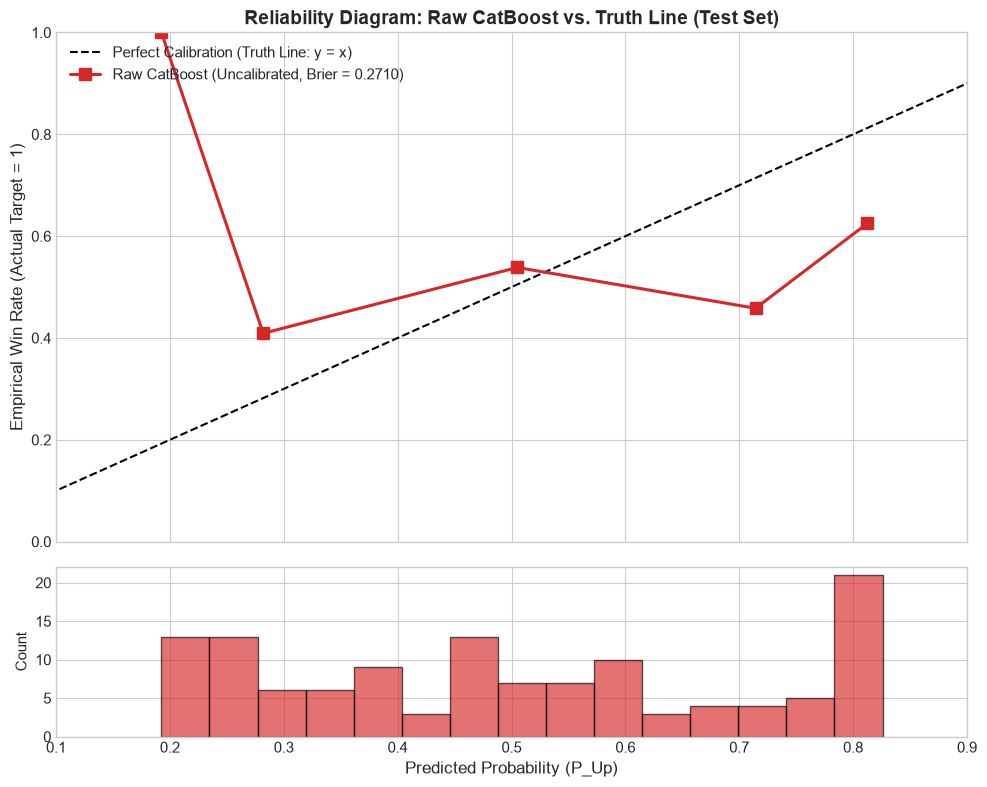

In [6]:
# 1. Calculate the Brier Score on unseen Test data
brier_raw = brier_score_loss(y_test, test_df['Prob_Raw'])
brier_baseline_coin = brier_score_loss(y_test, np.full_like(y_test, 0.5, dtype=float))

print('=' * 65)
print('📈 PROBABILITY ERROR METRICS (Test Set):')
print(f'  - Raw CatBoost Brier Score : {brier_raw:.4f}')
print(f'  - 50/50 Coin Toss Benchmark: {brier_baseline_coin:.4f}')
print('=' * 65)

# 2. Calculate the Calibration Curve (5 probability bins)
prob_true_raw, prob_pred_raw = calibration_curve(y_test, test_df['Prob_Raw'], n_bins=5, strategy='uniform')

# 3. Print a clean bin-by-bin mapping table
print('\n🔍 BIN-BY-BIN CONFIDENCE vs. REALITY BREAKDOWN:')
print(f'{"Bin #":<6} | {"Model Claim (Predicted)":<24} | {"Actual Reality (Win Rate)":<26} | {"Distortion Gap":<15}')
print('-' * 77)
for i, (p_pred, p_true) in enumerate(zip(prob_pred_raw, prob_true_raw)):
    gap = p_pred - p_true
    diagnosis = 'Overconfident' if gap > 0.05 else ('Underconfident' if gap < -0.05 else 'Well-Calibrated')
    print(f'Bin {i+1:<2} | {p_pred:>20.1%}     | {p_true:>22.1%}     | {gap:>+6.1%} ({diagnosis})')

# 4. Plot the Reliability Diagram (Industry Standard Two-Panel Chart)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), gridspec_kw={'height_ratios': [3, 1]}, sharex=True)

# Top Panel: Calibration Curve
ax1.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Perfect Calibration (Truth Line: y = x)')
ax1.plot(prob_pred_raw, prob_true_raw, 's-', color='#d62728', lw=2.2, markersize=8, label=f'Raw CatBoost (Uncalibrated, Brier = {brier_raw:.4f})')
ax1.set_ylabel('Empirical Win Rate (Actual Target = 1)', fontsize=12)
ax1.set_title('Reliability Diagram: Raw CatBoost vs. Truth Line (Test Set)', fontsize=14, fontweight='bold')
ax1.legend(loc='upper left', fontsize=11)
ax1.set_xlim([0.1, 0.9])
ax1.set_ylim([0.0, 1.0])

# Bottom Panel: Prediction Frequency Histogram
ax2.hist(test_df['Prob_Raw'], bins=15, color='#d62728', alpha=0.65, edgecolor='black')
ax2.set_xlabel('Predicted Probability (P_Up)', fontsize=12)
ax2.set_ylabel('Count', fontsize=11)

plt.tight_layout()
plt.show()

---
## 🛠️ Cell 7: Probability Calibration (Platt Scaling vs. Isotonic Regression)

Now we fix the model's overconfidence using our two calibrator algorithms:
1. **Platt Scaling**: Uses `LogisticRegression` to fit a smooth S-curve mapping `Prob_Raw` to reality on the calibration fold.
2. **Isotonic Regression**: Uses `IsotonicRegression` to fit a monotonic step-wise curve on the calibration fold.

Both models are trained strictly on the out-of-sample **Calibration Fold** `(calib_df['Prob_Raw'], y_calib)` and evaluated on the unseen **Test Fold**.

📉 BRIER SCORE SCOREBOARD (Unseen Test Set):
  1. Raw CatBoost (Uncalibrated) : 0.2710
  2. Platt Scaling (Sigmoid)     : 0.2489
  3. Isotonic Regression         : 0.2526


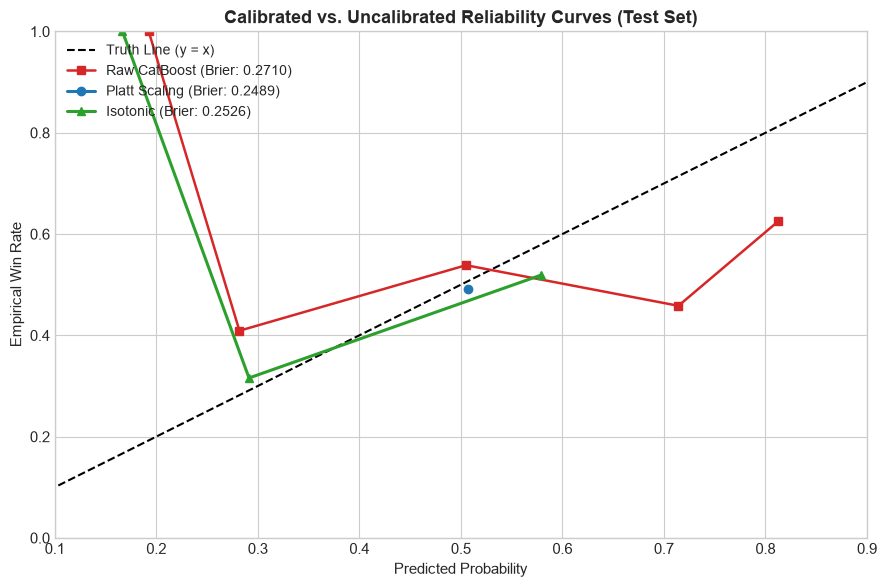

In [7]:
# 1. Fit Platt Scaling (Logistic Regression on raw probabilities)
platt_model = LogisticRegression()
platt_model.fit(calib_df[['Prob_Raw']], y_calib)

# 2. Fit Isotonic Regression on raw probabilities
iso_model = IsotonicRegression(out_of_bounds='clip')
iso_model.fit(calib_df['Prob_Raw'], y_calib)

# 3. Predict calibrated probabilities on unseen Test data
test_df['Prob_Platt'] = platt_model.predict_proba(test_df[['Prob_Raw']])[:, 1]
test_df['Prob_Isotonic'] = iso_model.predict(test_df['Prob_Raw'])

# 4. Compare Brier Scores (Lower is better!)
brier_platt = brier_score_loss(y_test, test_df['Prob_Platt'])
brier_iso = brier_score_loss(y_test, test_df['Prob_Isotonic'])

print('=' * 55)
print('📉 BRIER SCORE SCOREBOARD (Unseen Test Set):')
print(f'  1. Raw CatBoost (Uncalibrated) : {brier_raw:.4f}')
print(f'  2. Platt Scaling (Sigmoid)     : {brier_platt:.4f}')
print(f'  3. Isotonic Regression         : {brier_iso:.4f}')
print('=' * 55)

# 5. Plot Calibration Curves Comparison
prob_true_platt, prob_pred_platt = calibration_curve(y_test, test_df['Prob_Platt'], n_bins=5, strategy='uniform')
prob_true_iso, prob_pred_iso = calibration_curve(y_test, test_df['Prob_Isotonic'], n_bins=5, strategy='uniform')

plt.figure(figsize=(9, 6))
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Truth Line (y = x)')
plt.plot(prob_pred_raw, prob_true_raw, 's-', color='#d62728', lw=1.8, label=f'Raw CatBoost (Brier: {brier_raw:.4f})')
plt.plot(prob_pred_platt, prob_true_platt, 'o-', color='#1f77b4', lw=2.2, label=f'Platt Scaling (Brier: {brier_platt:.4f})')
plt.plot(prob_pred_iso, prob_true_iso, '^-', color='#2ca02c', lw=2.2, label=f'Isotonic (Brier: {brier_iso:.4f})')

plt.title('Calibrated vs. Uncalibrated Reliability Curves (Test Set)', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Probability', fontsize=11)
plt.ylabel('Empirical Win Rate', fontsize=11)
plt.xlim([0.1, 0.9])
plt.ylim([0.0, 1.0])
plt.legend(loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()